In [68]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

# Display dataset
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


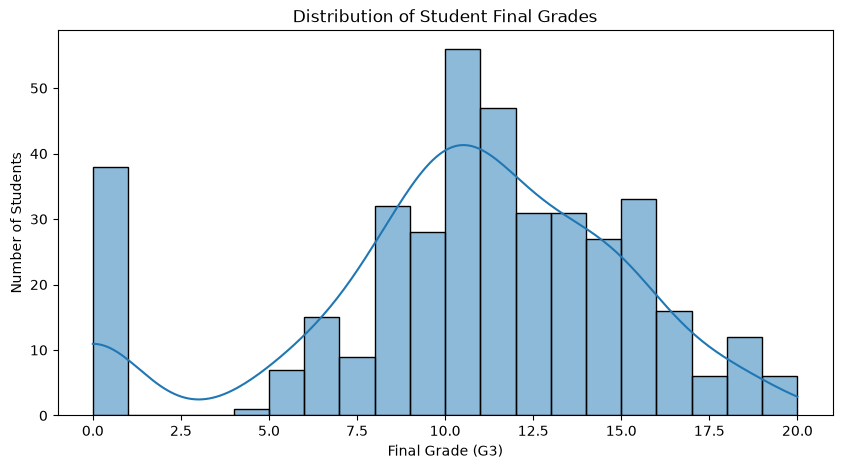

In [69]:

# Student Final Grade Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="G3",
    bins=20,
    kde=True
)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

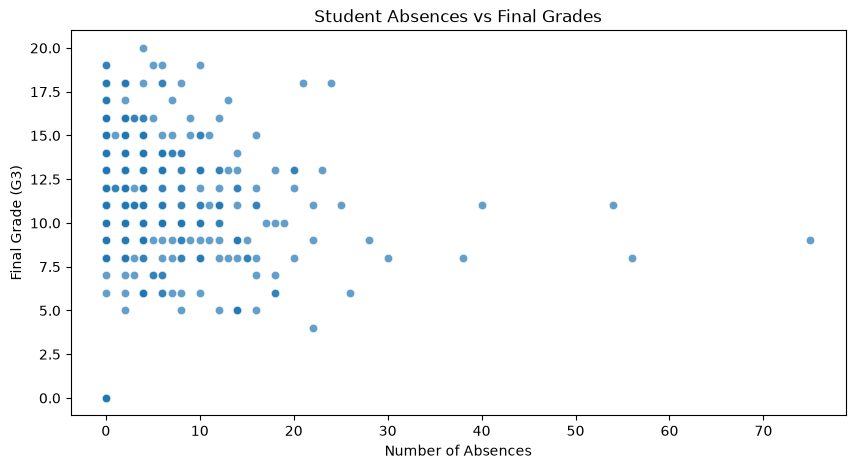

In [70]:

# Relationship Between Absences and Final Grades

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3",
    alpha=0.7
)

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.show()

In [71]:

# Correlation between Absences and Final Grades

correlation = df["absences"].corr(df["G3"])

print("Absences vs Final Grades Correlation")
print("------------------------------------")
print("Correlation Coefficient:", round(correlation, 3))

if correlation < 0:
    print("Interpretation: Negative relationship")
elif correlation > 0:
    print("Interpretation: Positive relationship")
else:
    print("Interpretation: No linear relationship")

Absences vs Final Grades Correlation
------------------------------------
Correlation Coefficient: 0.034
Interpretation: Positive relationship


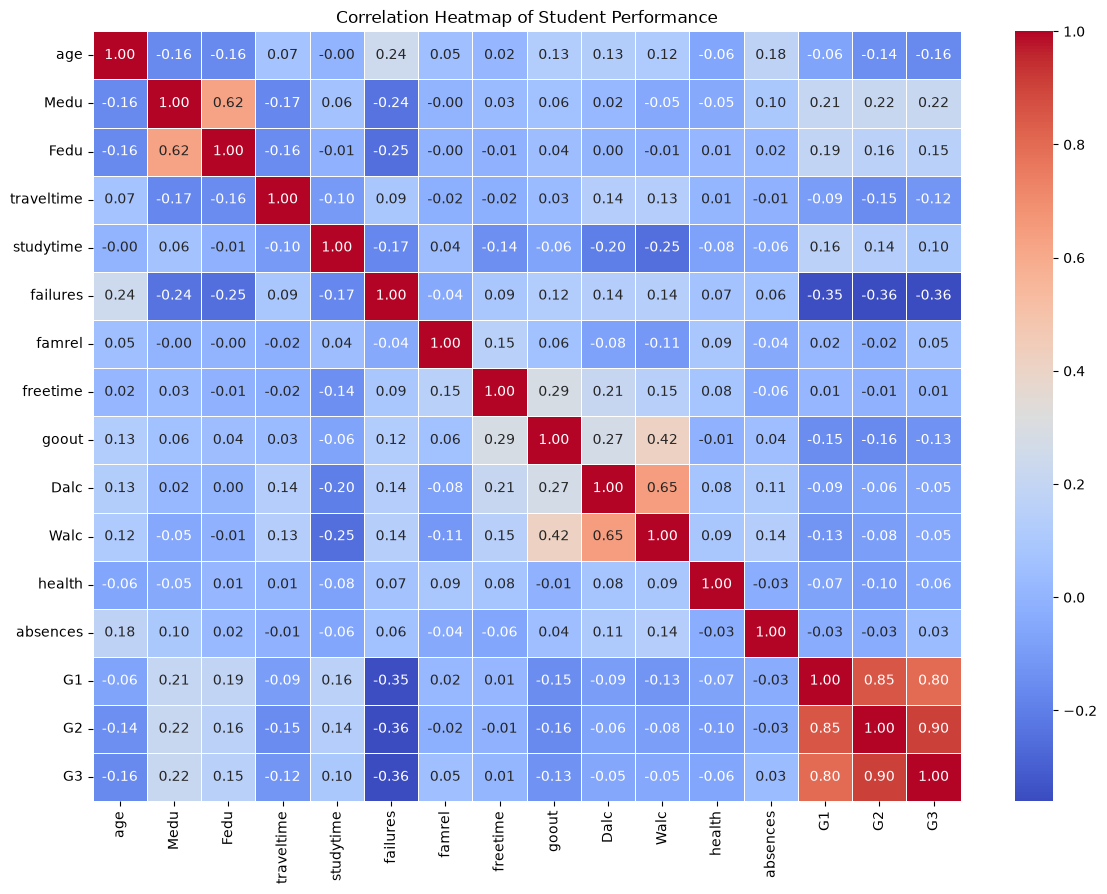

In [72]:

# Correlation Heatmap

numeric_data = df.select_dtypes(include=["int64", "float64"])

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance")
plt.show()

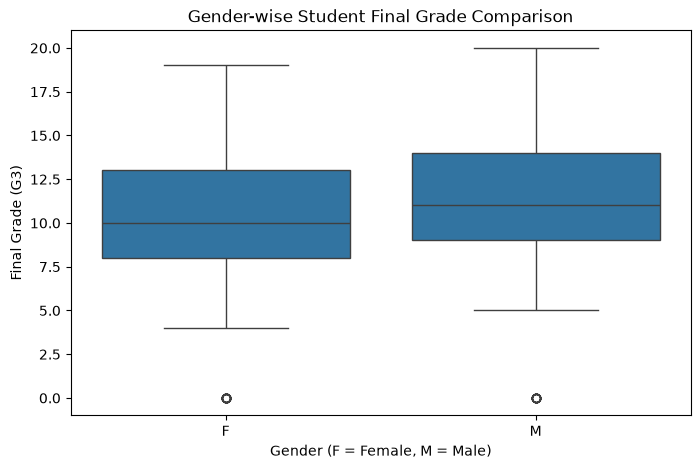

Average Final Grades by Gender:
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64

Student Count by Gender:
sex
F    208
M    187
Name: count, dtype: int64


In [73]:

# Gender-wise Student Performance Analysis

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="G3"
)

plt.title("Gender-wise Student Final Grade Comparison")
plt.xlabel("Gender (F = Female, M = Male)")
plt.ylabel("Final Grade (G3)")

plt.show()

# Average grades by gender
print("Average Final Grades by Gender:")
print(df.groupby("sex")["G3"].mean())

# Number of students by gender
print("\nStudent Count by Gender:")
print(df["sex"].value_counts())

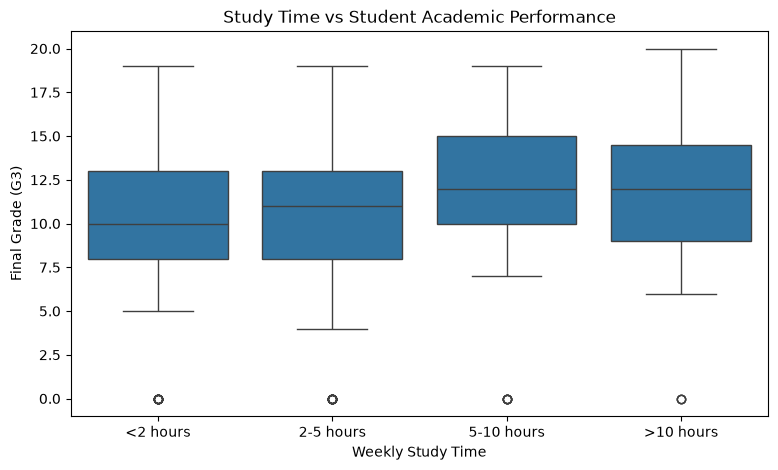

Average Final Grade by Study Time:
studytime
1    10.05
2    10.17
3    11.40
4    11.26
Name: G3, dtype: float64


In [74]:

# Study Time vs Final Grades

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Student Academic Performance")
plt.xlabel("Weekly Study Time")
plt.ylabel("Final Grade (G3)")

plt.xticks(
    [0, 1, 2, 3],
    ["<2 hours", "2-5 hours", "5-10 hours", ">10 hours"]
)

plt.show()

# Average grades by study time
print("Average Final Grade by Study Time:")
print(df.groupby("studytime")["G3"].mean().round(2))

In [75]:

# Student Academic Risk Classification

def classify_risk(grade):
    if grade < 10:
        return "High Risk"
    elif grade < 15:
        return "Medium Risk"
    else:
        return "Low Risk"

df["risk_level"] = df["G3"].apply(classify_risk)

# Display risk distribution
print("Student Academic Risk Distribution")
print("-----------------------------------")

print(df["risk_level"].value_counts())

# Risk percentage
print("\nRisk Percentage:")
print(
    (df["risk_level"].value_counts(normalize=True) * 100)
    .round(2)
)

Student Academic Risk Distribution
-----------------------------------
risk_level
Medium Risk    192
High Risk      130
Low Risk        73
Name: count, dtype: int64

Risk Percentage:
risk_level
Medium Risk    48.61
High Risk      32.91
Low Risk       18.48
Name: proportion, dtype: float64


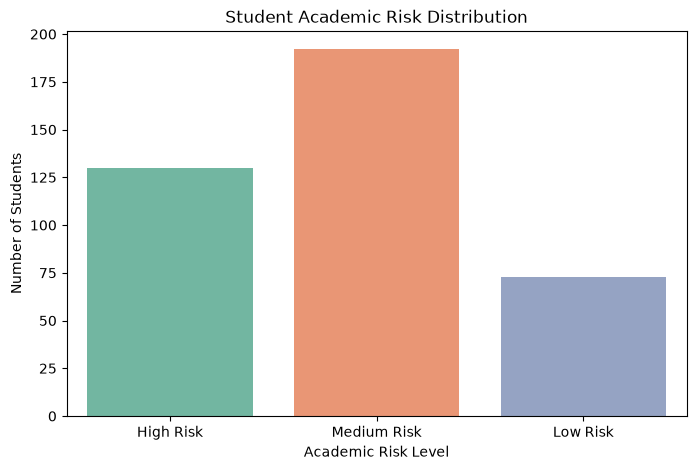

In [76]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="risk_level",
    hue="risk_level",
    order=["High Risk", "Medium Risk", "Low Risk"],
    palette="Set2",
    legend=False
)

plt.title("Student Academic Risk Distribution")
plt.xlabel("Academic Risk Level")
plt.ylabel("Number of Students")

plt.show()

In [77]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select student performance features
features = df[["G1", "G2", "absences", "studytime", "failures"]]

# Scale the data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(scaled_features)

# Display cluster distribution
print("Student Cluster Distribution:")
print(df["cluster"].value_counts().sort_index())

# Cluster-wise average performance
print("\nCluster Performance:")
print(df.groupby("cluster")[["G1", "G2", "G3"]].mean().round(2))

Student Cluster Distribution:
cluster
0    199
1    154
2     42
Name: count, dtype: int64

Cluster Performance:
            G1     G2     G3
cluster                     
0         9.11   8.92   8.43
1        14.31  14.21  14.40
2         6.98   6.38   5.21


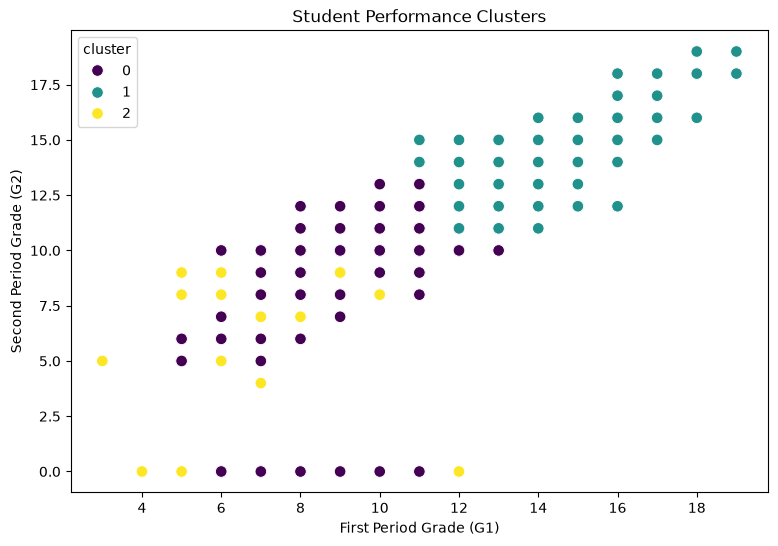

In [78]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="G1",
    y="G2",
    hue="cluster",
    palette="viridis",
    s=70
)

plt.title("Student Performance Clusters")
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Second Period Grade (G2)")

plt.show()